# Options Trading Toolkit: IV, Greeks, and Strategy Backtests

### Execution environment

This notebook uses live Yahoo Finance data and requires network access. Run it from the repository root. It does not upgrade packages automatically; in a fresh environment, install the release shown in `pyproject.toml` before execution.

## Workflow overview

This notebook demonstrates the options analytics project. It screens implied volatility term structure, backtests an earnings straddle idea, and visualizes option Greeks across strikes. Together these examples connect pricing, volatility, sensitivities, and strategy testing.


In [4]:
# Fresh environment only: %pip install "riskoptima==2.8.0"

In [5]:
import pandas as pd
from riskoptima import RiskOptima

import warnings
warnings.filterwarnings(
    "ignore", 
    category=FutureWarning, 
    message=".*DataFrame.std with axis=None is deprecated.*"
)
print(RiskOptima.VERSION)

2.8.0


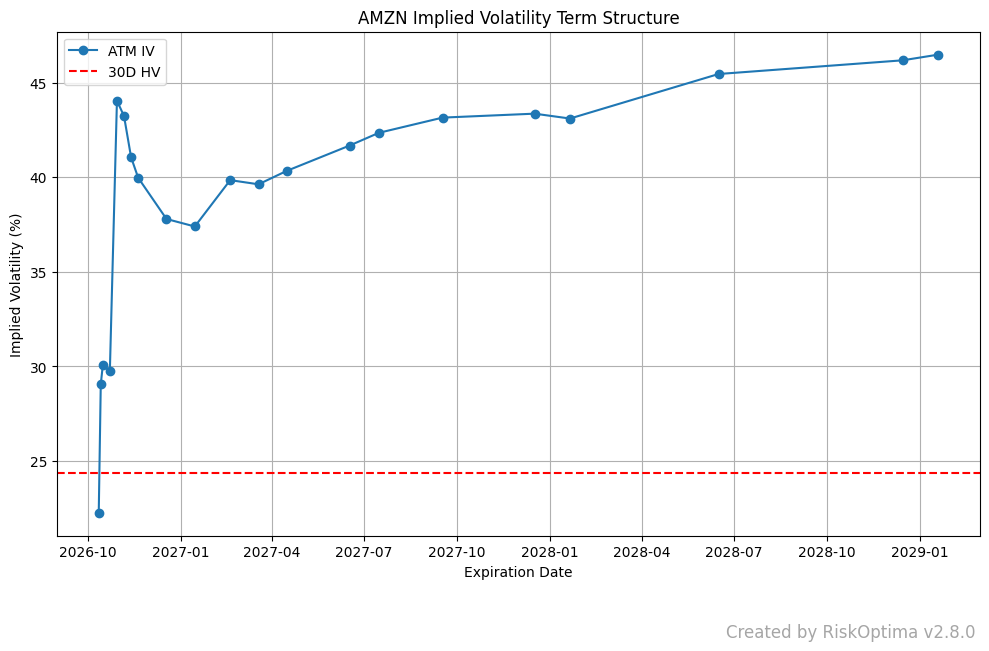

In [6]:
RiskOptima.implied_volatility_screener(symbol='AMZN')

### 📈 AMZN Implied Volatility Term Structure

This chart displays the **ATM (At-the-Money) Implied Volatility** for AMZN across upcoming option expiration dates. 

- The **blue line** shows the implied volatility of ATM options for each expiry.
- The **red dashed line** represents the **30-day historical volatility (HV)** as a benchmark.

#### 🔍 What It Shows:
- **Near-term expirations (May 2025)** have elevated IV, likely due to an upcoming earnings event or macro announcement.
- IV **rapidly drops off** into the summer, then **flattens and gradually rises** over longer-dated expiries.
- The **spread between IV and HV** suggests that **short-term options are rich** in premium relative to realized vol.

> 💡 This term structure helps you decide whether to buy or sell options. Elevated IV above HV usually favors **selling premium**, while discounted IV may signal a **buy vol** opportunity.

       abs_move  straddle_cost     profit
count  2.000000       2.000000   2.000000
mean   3.200005      10.941500  -7.741495
std    3.012271       3.193294   6.205565
min    1.070007       8.683500 -12.129492
25%    2.135006       9.812500  -9.935494
50%    3.200005      10.941500  -7.741495
75%    4.265003      12.070500  -5.547497
max    5.330002      13.199500  -3.353498


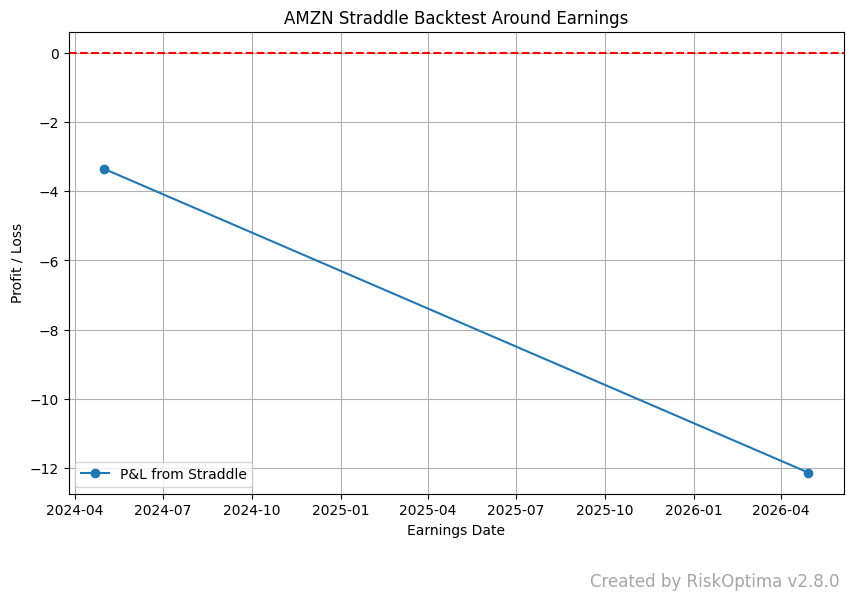

In [8]:
RiskOptima.straddle_backtester(symbol='AMZN', window_before=5, window_after=1)

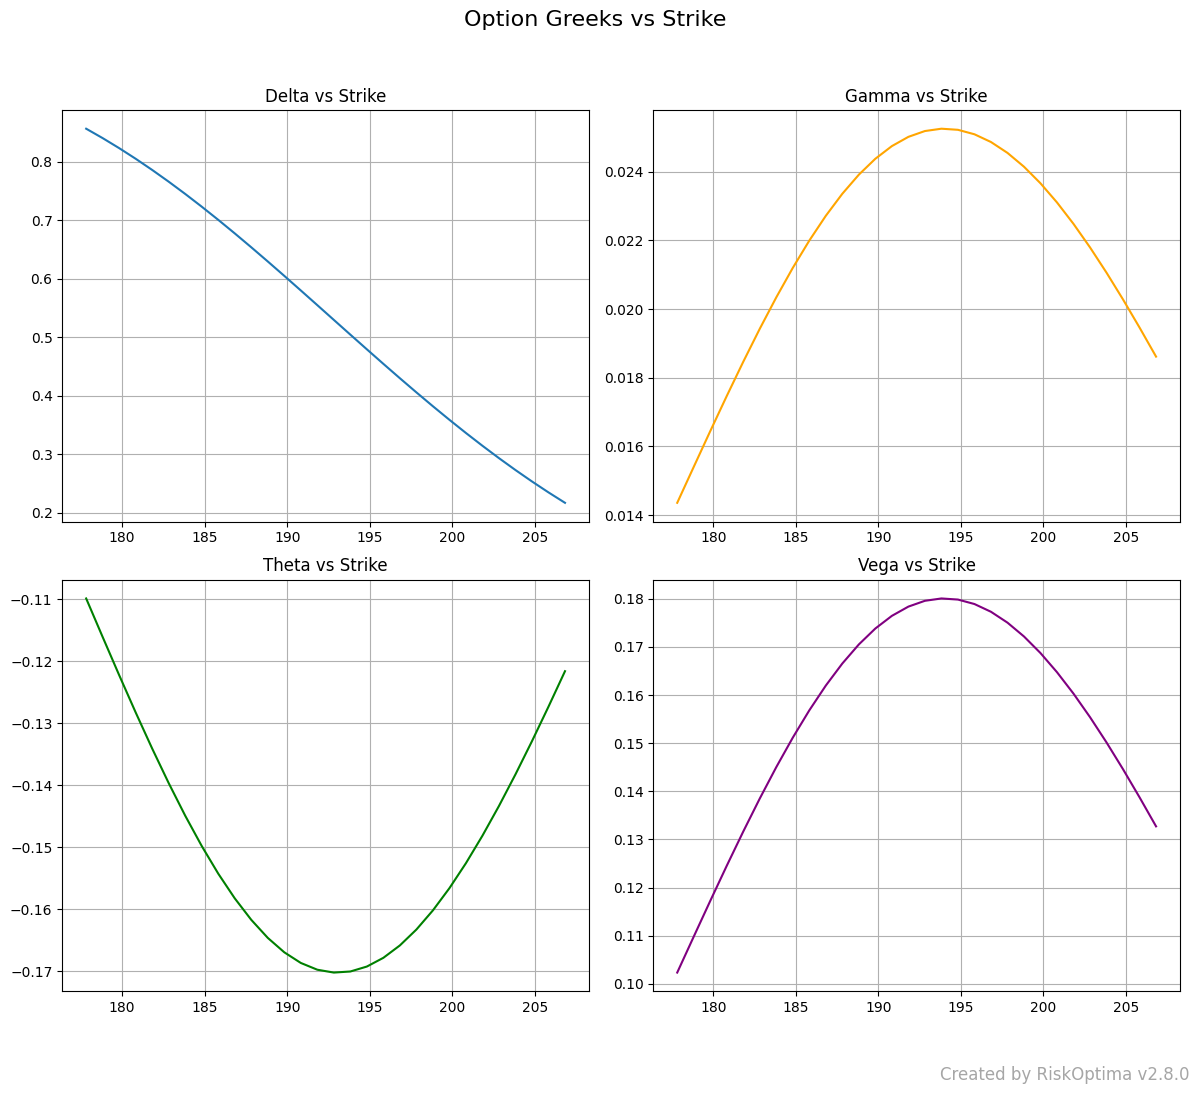

In [9]:
RiskOptima.greeks_simulator(S=192.82, T_days=20, sigma=0.35, option_type='call')